# 📰🤖 Fake News Detection with LSTM | Separating Fact from Fiction

## 📖 Introduction

Fake news is one of the biggest threats in today's information-driven world, spreading faster than ever across social media and news platforms.  
In this project, I set out to build an intelligent fake news detector using a Long Short-Term Memory (LSTM) network.  
By combining natural language processing (NLP) techniques with deep learning, the model analyzes the subtle patterns in text that separate real journalism from misinformation.  
From initial data exploration to model tuning and evaluation, this project follows a hands-on, data-driven journey to create a powerful and reliable fake news classification system.

---

## 🛠 Project Structure

### 1. Data Collection and Exploration
- Loading and inspecting the dataset.
- Handling missing values and basic preprocessing.
- Exploratory Data Analysis (EDA) to understand text characteristics.

### 2. Data Preprocessing
- Text cleaning (lowercasing, removing punctuation, stopwords, etc.).
- Tokenization and padding sequences for LSTM input.

### 3. Model Building
- Designing the LSTM architecture.
- Adding embedding layers, dropout, and dense layers.
- Compiling the model with appropriate loss and optimizer.
- Train-test split.

### 4. Model Training
- Training the LSTM model on the prepared dataset.
- Monitoring performance with accuracy and loss curves.

### 5. Model Evaluation
- Evaluating performance on the test set.
- Confusion matrix, precision, recall, and F1 score analysis.
- Interpretation of results.
- Challenges encountered and how they were addressed.

### 6. Conclusion and Future Work
- Summary of findings.
- Suggestions for future improvements (e.g., using bidirectional LSTM, adding attention mechanisms, experimenting with larger datasets).

---
### About Dataset
#### The dataset is separated in two files:
Fake.csv (23502 fake news article)
True.csv (21417 true news article)
#### Dataset columns:
1. **Title**: title of news article
2. **Text**: body text of news article
3. **Subject**: subject of news article
4. **Date**: publish date of news article

### Data Collection and Exploration

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Loading and inspecting the datasets
fake_df = pd.read_csv("data/Fake.csv")
real_df = pd.read_csv("data/True.csv")

In [7]:
fake_df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [9]:
real_df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [11]:
fake_df.info(), real_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB


(None, None)

#### Basic preprocessing

In [14]:
# preprocessing function
def data_preprocessor(fake_df, real_df):
    ## Adding labels
    fake_df['label']= 0
    real_df['label']= 1
    # Combine the two datasets into one
    news_df = pd.concat([fake_df,real_df], axis=0, ignore_index=True)
    # Removing useless data (title, subject, date)
    news_df.drop(['title', 'subject', 'date'], axis = 1, inplace = True)
    # Shuffling the data (random sampling)
    data = news_df.sample(frac=1)
    # Reseting the index then removing it
    data.reset_index(inplace=True)
    data.drop(['index'], axis = 1, inplace = True)

    return data

In [16]:
news_data = data_preprocessor(fake_df, real_df)

In [18]:
news_data.head()

,text,label
0,EDITOR S NOTE: We recognize the following eloq...,0
1,WASHINGTON (Reuters) - U.S. presidential candi...,1
2,WASHINGTON (Reuters) - Some U.S. intelligence ...,1
3,BRUSSELS (Reuters) - The collapse of talks on ...,1
4,MOSCOW (Reuters) - Russian Foreign Minister Se...,1


#### Exploratory Data Analysis

In [21]:
# Checking for nulls or empty values
news_data.isnull().sum()

text     0
label    0
dtype: int64

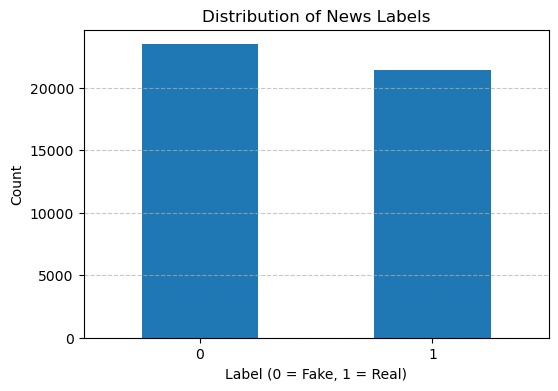

In [23]:
# Data distribution
label_counts = news_data['label'].value_counts()

plt.figure(figsize=(6, 4))
label_counts.plot(kind='bar')
plt.title('Distribution of News Labels')
plt.xlabel('Label (0 = Fake, 1 = Real)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Data Preprocessing
1. Text cleaning (lowercasing, removing punctuation, stopwords, etc.).
2. Tokenization and padding sequences for LSTM input.

In [26]:
# Text Cleaning
import nltk
import re
from nltk.corpus import stopwords

In [28]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /Users/jean-
[nltk_data]     emmanuelkouadio/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [30]:
from nltk.stem.porter import PorterStemmer
from tqdm import tqdm  # Import tqdm for progress bar

In [32]:
ps = PorterStemmer()
stop_words = set(stopwords.words('english'))  # Load stopwords once

corpus = []

# Use tqdm to show a progress bar
for i in tqdm(range(len(news_data)), desc="Processing Texts"):
    text = news_data['text'][i]
    text = re.sub(r'https?://\S+|www\.\S+', '', text)  # Remove URLs
    text = re.sub(r'<.*?>', '', text)                  # Remove HTML tags
    text = re.sub(r'[^\w\s]', '', text)                 # Remove punctuation
    text = re.sub(r'\d', '', text)                      # Remove digits
    text = re.sub(r'\n', ' ', text)                     # Remove newline characters
    text = text.lower()                                 # Lowercase
    text = text.split()                                 # Tokenize (split into words)
    
    text = [ps.stem(word) for word in text if word not in stop_words]  # Remove stopwords + stem
    text = ' '.join(text)  # Join words with spaces
    corpus.append(text)

Processing Texts: 100%|██████████████████| 44898/44898 [01:23<00:00, 538.33it/s]


In [34]:
# Tokenization and padding sequences for LSTM input
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences 

In [36]:
# Define vocabulary size
vocab_size = 10000 
# Create and fit the tokenizer
tokenizer = Tokenizer(num_words=vocab_size, oov_token='<OOV>')
tokenizer.fit_on_texts(corpus)

In [38]:
# Convert the texts into sequences
sequences = tokenizer.texts_to_sequences(corpus)

# Pad the sequences to the same length
max_length = 300 
X = pad_sequences(sequences, maxlen=max_length, padding='post')

In [40]:
# Set the target variable
y = news_data['label'].values

### Model Building
1. Designing the LSTM architecture.
2. Adding embedding layers, dropout, and dense layers.
3. Compiling the model with appropriate loss and optimizer.
4. Train test Split

In [47]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.layers import Dropout

# Model building and compiling
embedding_dim = 100  # you can set 50, 100, 128 depending on model size

model = Sequential()
model.add(Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length))
model.add(LSTM(128))  # 128 LSTM units
model.add(Dropout(0.3)) #  to prevent overfitting
model.add(Dense(1, activation='sigmoid'))  # Binary classification (fake/real)

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_2 (Embedding)     (None, 300, 100)          1000000   
                                                                 
 lstm_3 (LSTM)               (None, 128)               117248    
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense (Dense)               (None, 1)                 129       
                                                                 
Total params: 1117377 (4.26 MB)
Trainable params: 1117377 (4.26 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [49]:
# Train test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Model Training
- Training the LSTM model on the prepared dataset.
- Monitoring performance with accuracy and loss curves.

In [52]:
# Model training
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop]
)

Epoch 1/10
562/562 [==============================] - 187s 331ms/step - loss: 0.4131 - accuracy: 0.8207 - val_loss: 0.2758 - val_accuracy: 0.9008
Epoch 2/10
562/562 [==============================] - 185s 330ms/step - loss: 0.2676 - accuracy: 0.9078 - val_loss: 0.2602 - val_accuracy: 0.9027
Epoch 3/10
562/562 [==============================] - 208s 370ms/step - loss: 0.2416 - accuracy: 0.9173 - val_loss: 0.1717 - val_accuracy: 0.9545
Epoch 4/10
562/562 [==============================] - 200s 356ms/step - loss: 0.5725 - accuracy: 0.6798 - val_loss: 0.5539 - val_accuracy: 0.6541
Epoch 5/10
562/562 [==============================] - 212s 377ms/step - loss: 0.4403 - accuracy: 0.7398 - val_loss: 0.1103 - val_accuracy: 0.9640
Epoch 6/10
562/562 [==============================] - 225s 401ms/step - loss: 0.0440 - accuracy: 0.9894 - val_loss: 0.0275 - val_accuracy: 0.9930
Epoch 7/10
562/562 [==============================] - 220s 391ms/step - loss: 0.0182 - accuracy: 0.9963 - val_loss: 0.0186 -

### 5. Model Evaluation
- Evaluating performance on the test set.
- Confusion matrix, precision, recall, and F1 score analysis.

In [55]:
# Evaluate the Model on Test Set
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy:.4f}")

281/281 [==============================] - 17s 61ms/step - loss: 0.0183 - accuracy: 0.9949
Test Accuracy: 0.9949


In [57]:
# Model prediction
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)  # Convert probabilities to 0 or 1

281/281 [==============================] - 18s 62ms/step


In [59]:
# Classification report 
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      4654
           1       0.99      1.00      0.99      4326

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



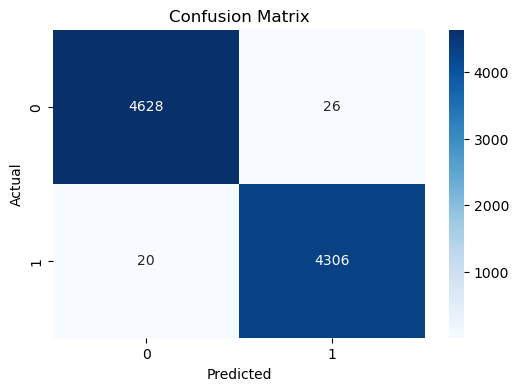

In [61]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

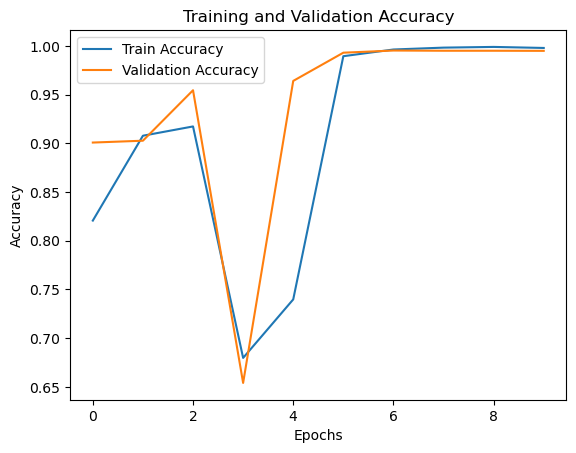

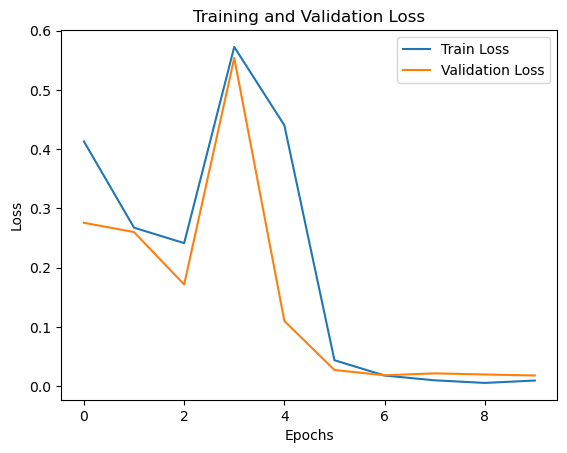

In [63]:
# Training Curves

# Plot accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [65]:
# Save the model
model.save('lstm_fake_news_detector.h5')

/opt/anaconda3/lib/python3.9/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


### 📜 Conclusion

In this project, we developed a Fake News Detector using an LSTM-based neural network.  
After comprehensive text preprocessing, tokenization, and sequence modeling, the model achieved an outstanding **99% test accuracy**.  
The precision, recall, and F1-scores for both fake and real news categories were approximately **99%-100%**, demonstrating exceptional model performance and robustness.

The confusion matrix and training-validation curves confirmed that the model generalized well to unseen data without overfitting.

This project highlights the effectiveness of deep learning techniques, particularly LSTM models, in tackling real-world text classification problems such as misinformation detection.

---

### 🚀 Future Work

To further enhance this project, the following improvements could be explored:

- **Integrating Pre-trained Embeddings**: Such as GloVe or Word2Vec to provide richer word representations.
- **Using Bidirectional LSTM**: To capture both past and future context in text sequences.
- **Applying Attention Mechanisms**: To help the model focus on the most informative parts of the articles.
- **Experimenting with Transformer Models (e.g., BERT)**: To leverage state-of-the-art performance in NLP tasks.
- **Adding Explainability Techniques**: Like LIME or SHAP to interpret model predictions.

Continued iteration and experimentation could yield even stronger fake news detection systems capable of handling increasingly complex and diverse news datasets.

---
